In [1]:
from astropy import units
from astropy.time import Time

from matplotlib import pyplot

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator
from src.selflensing.models import SelfLensingSystem

In [2]:
LENSING_METHOD = 'IntegratedWittMao'

In [3]:
sls = SelfLensingSystem(
    a=2.8 * units.AU,
    b=0 * units.dimensionless_unscaled,
    Macc=13*units.M_sun,
    Mcomp=4*units.M_sun,
    Rcomp=10*units.R_sun,
    e=0 * units.dimensionless_unscaled,
)
sls.porb

<Quantity 415.0601257 d>

In [4]:
sls.rE(), sls.tau_eff

(<Quantity 0.25778432 solRad>, <Quantity 2.25088478 d>)

In [5]:
start_time = Time("2025-01-01")
end_time = Time("2026-01-01")
peak_time = Time("2025-02-01")

In [6]:
lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=False, db=False, sl=True, lensing_method=LENSING_METHOD)
rvg = RVGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time)

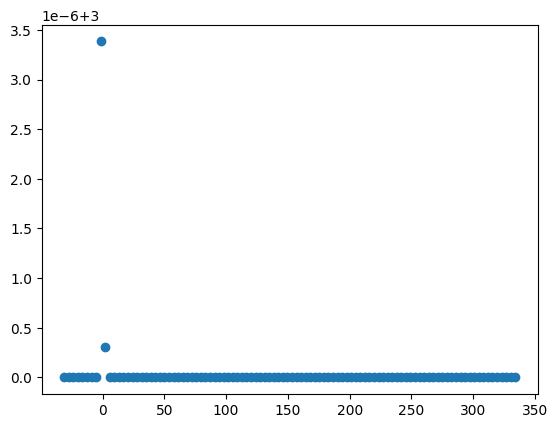

In [7]:
pyplot.scatter((lcg.time_offsets), lcg.flux_array)

In [8]:
import numpy
peak_mag = numpy.max(lcg.timeseries['flux']) / numpy.median(lcg.timeseries['flux'])
min_mag = peak_mag * 0.999
max_mag = peak_mag * 1.001
min_mag, peak_mag, max_mag

(<Quantity 0.99900113>, <Quantity 1.00000113>, <Quantity 1.00100113>)

In [9]:
import rustlens
rustlens.witt_mao_magnification([0], sls.rE().value, sls.Rcomp.value)

[1.0013281731326182]

In [ ]:
non_detection_times = [t for t in lcg.time_offsets if t not in lcg.peak_time_offsets]

In [12]:
sls.tau_eff, sls.rE(), sls.b

(<Quantity 2.25088478 d>, <Quantity 0.25778432 solRad>, <Quantity 0.>)

In [13]:
from src.selflensing.calc import estimate_porb

p = estimate_porb(sls.tau_eff, min_mag, max_mag, sls.Rcomp)
p

/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:659: RuntimeWarning: invalid value encountered in arcsin
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


[<Quantity [4.50176955e+00, 1.52066760e+05] d>]

In [14]:
from src.selflensing.calc import eliminate_times
sls.porb, eliminate_times(p, sls.tau_eff, non_detection_times)

(<Quantity 415.0601257 d>,
 [(<Quantity 169.21635148 d>, <Quantity 170.65233539 d>),
  (<Quantity 172.90322017 d>, <Quantity 174.33920408 d>),
  (<Quantity 176.59008885 d>, <Quantity 178.02607276 d>),
  (<Quantity 180.27695754 d>, <Quantity 181.71294145 d>),
  (<Quantity 183.96382623 d>, <Quantity 185.39981014 d>),
  (<Quantity 187.65069491 d>, <Quantity 189.08667882 d>),
  (<Quantity 191.3375636 d>, <Quantity 192.77354751 d>),
  (<Quantity 195.02443229 d>, <Quantity 196.4604162 d>),
  (<Quantity 198.71130097 d>, <Quantity 200.14728488 d>),
  (<Quantity 202.39816966 d>, <Quantity 203.83415357 d>),
  (<Quantity 206.08503835 d>, <Quantity 207.52102226 d>),
  (<Quantity 209.77190704 d>, <Quantity 211.20789094 d>),
  (<Quantity 213.45877572 d>, <Quantity 214.89475963 d>),
  (<Quantity 217.14564441 d>, <Quantity 218.58162832 d>),
  (<Quantity 220.8325131 d>, <Quantity 222.26849701 d>),
  (<Quantity 224.51938178 d>, <Quantity 225.95536569 d>),
  (<Quantity 228.20625047 d>, <Quantity 229.6422

In [24]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=1 * rvg.units,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    nsteps=5000,
    nwalkers=20,
    burn=10,
    lensing_method=LENSING_METHOD,
)
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time, lensing_method=LENSING_METHOD)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:659: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


ValueError: Probability function returned NaN

In [ ]:
sls.a, sls.Macc, sls.b, sls.e, sls.periapsis_phase, sls.porb

(<Quantity 20. AU>,
 <Quantity 1.3 solMass>,
 <Quantity 0.>,
 <Quantity 0.>,
 <Quantity 0. rad>,
 <Quantity 14190.75446116 d>)

In [ ]:
sls_fit.a, sls_fit.Macc, sls_fit.b, sls_fit.e, sls_fit.periapsis_phase, sls_fit.porb

(<Quantity 4.5537544 AU>,
 <Quantity 0.5 solMass>,
 <Quantity 9.98771027>,
 <Quantity 0.76710854>,
 <Quantity 4.04549704 rad>,
 <Quantity 1673.19507101 d>)

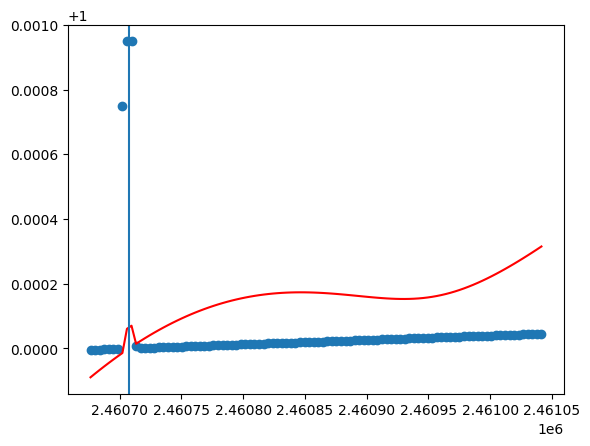

In [ ]:
pyplot.scatter(lcg.times.jd, lcg.flux_array)
pyplot.plot(lcg_fit.times.jd, lcg_fit.flux_array, c='red')
pyplot.axvline(peak_time.jd)

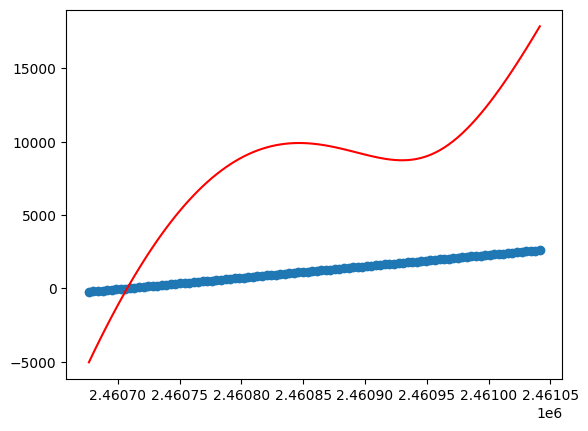

In [ ]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

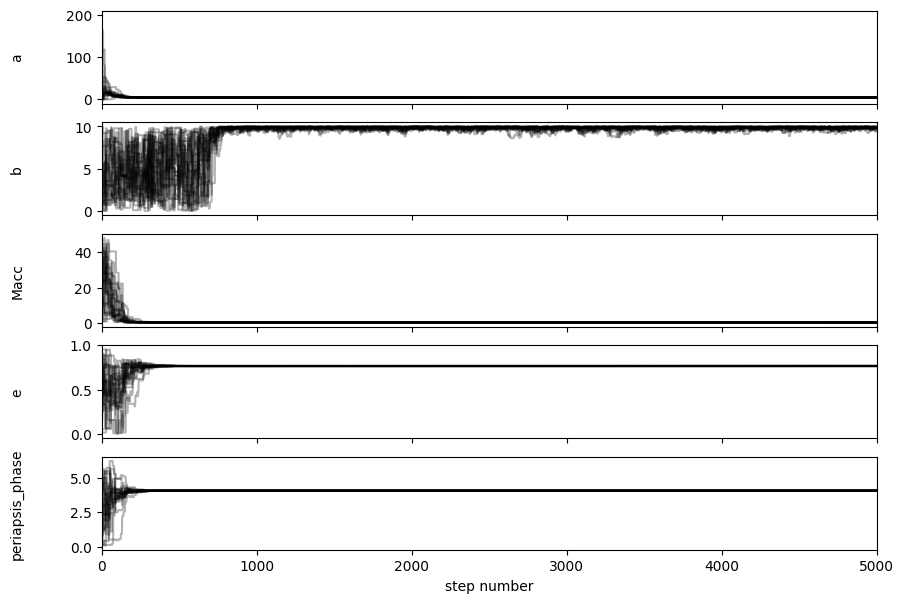

In [ ]:
from matplotlib import pyplot as plt
labels = ["a", "b", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

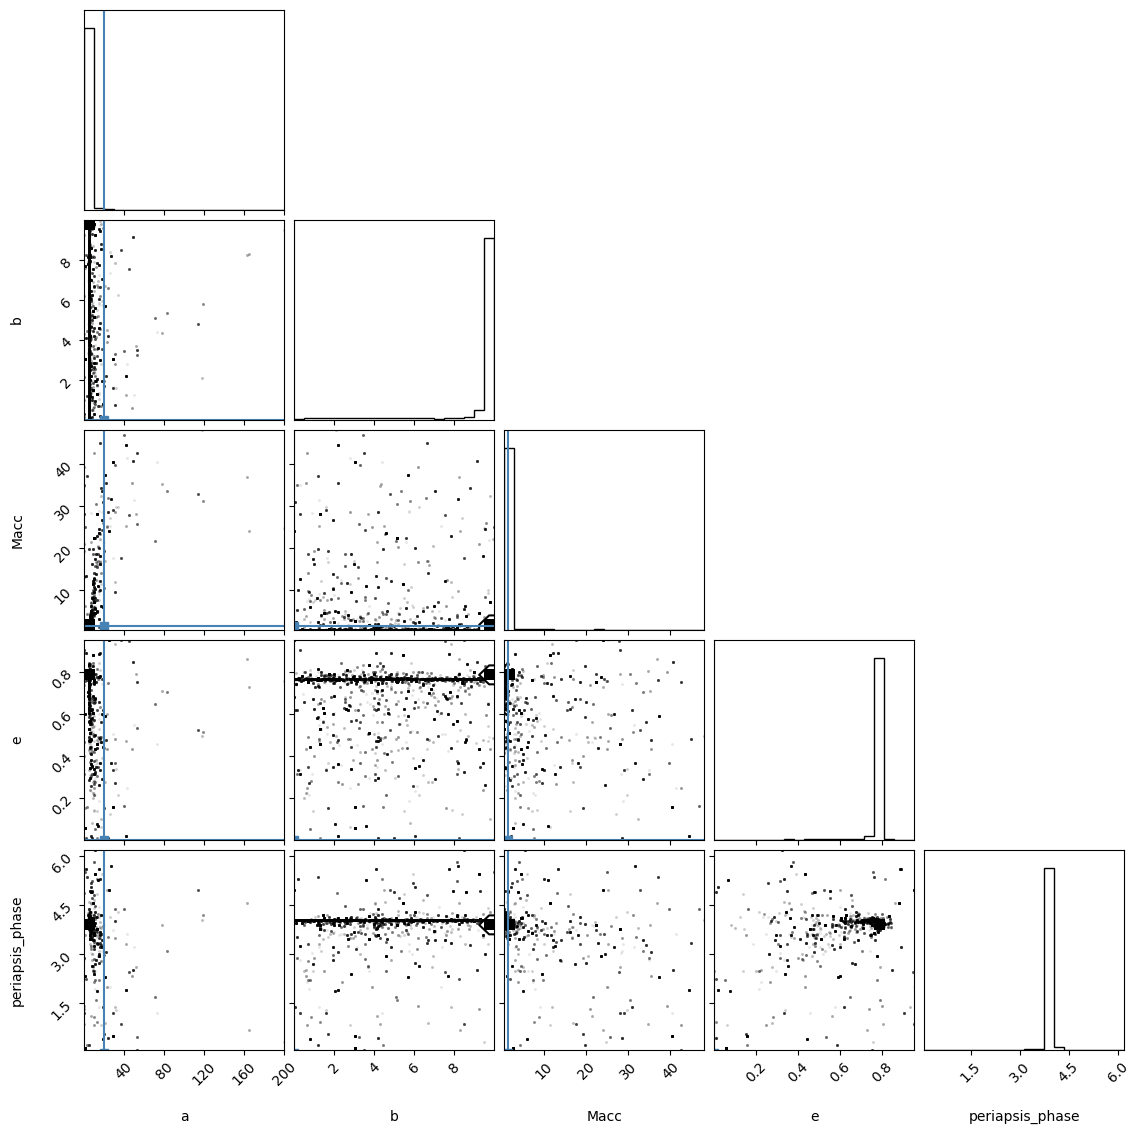

In [ ]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=[sls.a.value, sls.b.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]
)